# Telco Churn Prediction

We are going to explore a Customer Churn in Telco. To acheive this, we are going to follow the steps below iteratively:

1. Cleaning
2. Exploratory Data Analysis
3. Preprocessing
4. Feature Engineering
5. Modelling
6. Evaluation

In [1]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns   

import warnings
warnings.filterwarnings('ignore')

from sklearn.metrics import recall_score, precision_score, f1_score, accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import KNNImputer, SimpleImputer


## Data Cleaning 

Next we want to clean the data, we are checking:
1. Missing Values
2. Adjust Data Types
3. Remove Duplicates
4. Data Formating and Standardization
5. Handle outliers 

In [2]:
# import dataset
bank_marketing = pd.read_csv('/Users/doluwamusolana/Documents/UTIVA/bank_marketing.csv')
bank_marketing.head()

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


In [3]:
bank_marketing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          45211 non-null  int64 
 1   job          44923 non-null  object
 2   marital      45211 non-null  object
 3   education    43354 non-null  object
 4   default      45211 non-null  object
 5   balance      45211 non-null  int64 
 6   housing      45211 non-null  object
 7   loan         45211 non-null  object
 8   contact      32191 non-null  object
 9   day_of_week  45211 non-null  int64 
 10  month        45211 non-null  object
 11  duration     45211 non-null  int64 
 12  campaign     45211 non-null  int64 
 13  pdays        45211 non-null  int64 
 14  previous     45211 non-null  int64 
 15  poutcome     8252 non-null   object
 16  y            45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [4]:
bank_marketing.describe()

,age,balance,day_of_week,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [5]:
#Collect Categorical Columns
bank_marketing.select_dtypes(include=['object']).columns
cat_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome', 'y']

In [6]:
# Check unique values for each categorical column
for col in cat_cols:
    print(bank_marketing[col].unique())

['management' 'technician' 'entrepreneur' 'blue-collar' nan 'retired'
 'admin.' 'services' 'self-employed' 'unemployed' 'housemaid' 'student']
['married' 'single' 'divorced']
['tertiary' 'secondary' nan 'primary']
['no' 'yes']
['yes' 'no']
['no' 'yes']
[nan 'cellular' 'telephone']
['may' 'jun' 'jul' 'aug' 'oct' 'nov' 'dec' 'jan' 'feb' 'mar' 'apr' 'sep']
[nan 'failure' 'other' 'success']
['no' 'yes']


### Inspect and Handle Missing Values

1. Nature of Missingness - MAR, MCAR, MNAR
2. Handling Technigues include
    - Deletion
    - Simple Impution
    - Advanced Imputation 

In [7]:
bank_marketing[bank_marketing.job.isna()].isna().sum()

age              0
job            288
marital          0
education      127
default          0
balance          0
housing          0
loan             0
contact        111
day_of_week      0
month            0
duration         0
campaign         0
pdays            0
previous         0
poutcome       255
y                0
dtype: int64

In [8]:
bank_marketing[bank_marketing.contact.isna()].isna().sum()

age                0
job              111
marital            0
education        677
default            0
balance            0
housing            0
loan               0
contact        13020
day_of_week        0
month              0
duration           0
campaign           0
pdays              0
previous           0
poutcome       12950
y                  0
dtype: int64

In [9]:
bank_marketing[bank_marketing.education.isna()].isna().sum()

age               0
job             127
marital           0
education      1857
default           0
balance           0
housing           0
loan              0
contact         677
day_of_week       0
month             0
duration          0
campaign          0
pdays             0
previous          0
poutcome       1534
y                 0
dtype: int64

In [10]:
bank_marketing[bank_marketing.poutcome.isna()].isna().sum()

age                0
job              255
marital            0
education       1534
default            0
balance            0
housing            0
loan               0
contact        12950
day_of_week        0
month              0
duration           0
campaign           0
pdays              0
previous           0
poutcome       36959
y                  0
dtype: int64

In [11]:
# Fill missing values in poutcome column with 'nonexistent'
bank_marketing['poutcome'] = bank_marketing['poutcome'].fillna('nonexistent')

#fill missing values in job with another category 'unknown'
bank_marketing['job'] = bank_marketing['job'].fillna('other')

#fill missing values in contact with another category 'unknown'
bank_marketing['contact'] = bank_marketing['contact'].fillna('unknown')

#fill missing values in education with another category 'unknown'
bank_marketing['education'] = bank_marketing['education'].fillna('unknown')

In [12]:
#bank_marketing.poutcome = np.where(bank_marketing.poutcome == 'other', 'nonexistent', bank_marketing.poutcome)

In [13]:
bank_marketing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          45211 non-null  int64 
 1   job          45211 non-null  object
 2   marital      45211 non-null  object
 3   education    45211 non-null  object
 4   default      45211 non-null  object
 5   balance      45211 non-null  int64 
 6   housing      45211 non-null  object
 7   loan         45211 non-null  object
 8   contact      45211 non-null  object
 9   day_of_week  45211 non-null  int64 
 10  month        45211 non-null  object
 11  duration     45211 non-null  int64 
 12  campaign     45211 non-null  int64 
 13  pdays        45211 non-null  int64 
 14  previous     45211 non-null  int64 
 15  poutcome     45211 non-null  object
 16  y            45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [14]:
#Check for Duplicates
bank_marketing.duplicated().sum()

np.int64(0)

**We have no duplicates**

#### Inspect for Outliers

In [51]:
bank_marketing.describe()

,age,balance,day_of_week,duration,campaign,pdays,previous
count,45184.000000,45184.000000,45184.000000,45184.000000,45184.000000,45184.000000,45184.000000
mean,40.935265,1362.445180,15.805883,256.692524,2.764009,40.185907,0.570954
std,10.619125,3045.455178,8.321679,249.012689,3.098708,100.073099,1.856686
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,318.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,2485.000000,63.000000,871.000000,41.000000


**The previous, pdays, campaign, duration columns seem to have outliers**

Let us investigate futher

<Axes: xlabel='previous', ylabel='Count'>

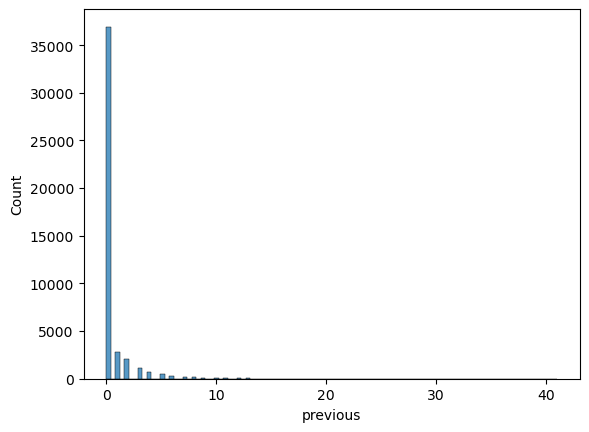

In [52]:
#
sns.histplot(bank_marketing['previous'], bins=100)

<Axes: ylabel='previous'>

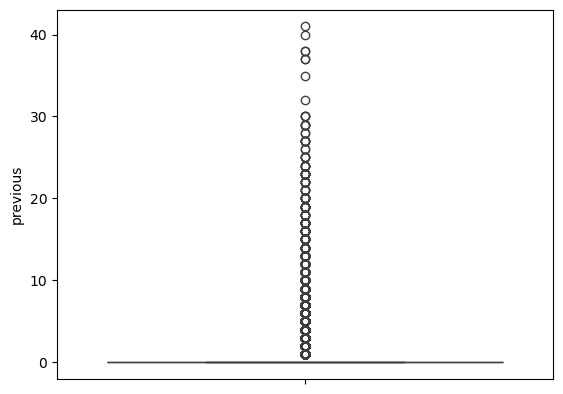

In [53]:
sns.boxplot(y='previous', data=bank_marketing)

***We would filter data above 50 because there are very rare compared to the size of the dataset**

In [54]:

bank_marketing = bank_marketing[bank_marketing.previous < 50]

<Axes: ylabel='previous'>

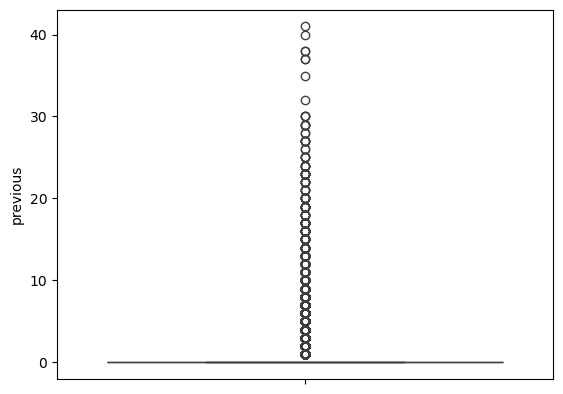

In [55]:
sns.boxplot(y='previous', data=bank_marketing)

In [56]:
bank_marketing[bank_marketing.previous > 30]

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
26668,51,entrepreneur,married,secondary,no,653,yes,no,cellular,20,nov,16,9,112,37,other,no
28498,49,management,single,tertiary,no,145,yes,no,cellular,29,jan,57,2,248,38,failure,no
37567,39,management,married,tertiary,no,0,yes,no,cellular,14,may,11,15,261,38,failure,no
39141,44,admin.,married,secondary,no,429,yes,yes,cellular,18,may,35,3,349,32,failure,no
42422,27,student,single,secondary,no,91,no,no,telephone,4,dec,157,6,95,37,other,no
42611,35,technician,single,secondary,no,4645,yes,no,cellular,11,jan,502,3,270,40,other,no
44484,28,management,single,tertiary,no,6791,no,no,telephone,9,aug,361,1,46,35,failure,no
44822,27,blue-collar,married,secondary,no,821,yes,yes,unknown,16,sep,23,1,778,41,other,no


**We would leave the previous column how it is and deal with other columns**


<Axes: ylabel='pdays'>

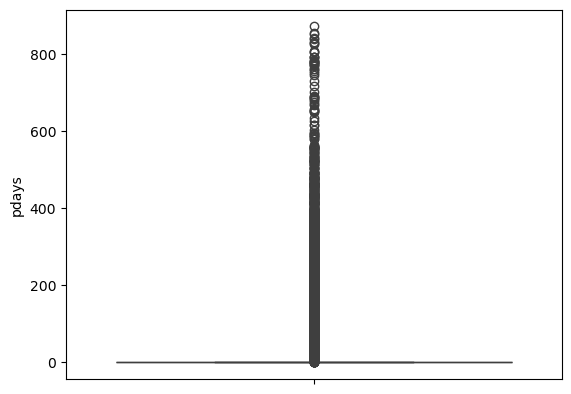

In [57]:
sns.boxplot(y='pdays', data=bank_marketing)

In [58]:
bank_marketing[bank_marketing.pdays > 400]

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
40506,38,unemployed,married,primary,no,7005,yes,no,cellular,7,jul,370,1,412,1,failure,yes
40590,42,management,single,tertiary,no,11008,no,no,cellular,28,jul,822,6,405,1,success,yes
40591,34,technician,married,secondary,no,603,yes,no,cellular,28,jul,51,4,434,1,failure,no
40711,57,services,married,secondary,no,2476,yes,no,cellular,7,aug,239,1,459,1,success,no
40751,33,management,married,tertiary,no,22867,yes,no,cellular,10,aug,73,1,440,2,failure,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45146,49,unemployed,divorced,tertiary,no,780,no,no,cellular,8,nov,148,1,871,2,failure,no
45154,63,retired,married,primary,no,3738,no,no,telephone,9,nov,301,1,456,4,failure,no
45171,33,admin.,single,secondary,no,690,no,no,cellular,10,nov,223,3,555,16,failure,no
45188,29,management,single,secondary,no,703,yes,no,cellular,16,nov,236,1,550,2,success,yes


<Axes: xlabel='pdays', ylabel='Count'>

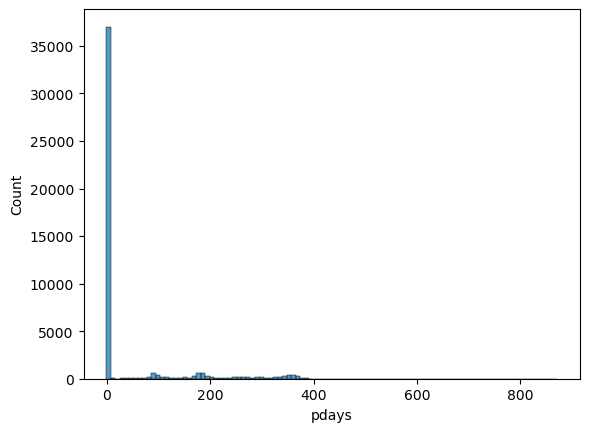

In [59]:
sns.histplot(bank_marketing['pdays'], bins=100)

<Axes: ylabel='campaign'>

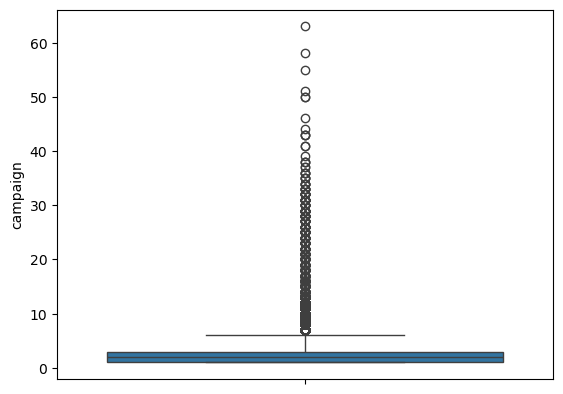

In [60]:
#checking for outliers in campaign column
sns.boxplot(y='campaign', data=bank_marketing)

<Axes: ylabel='duration'>

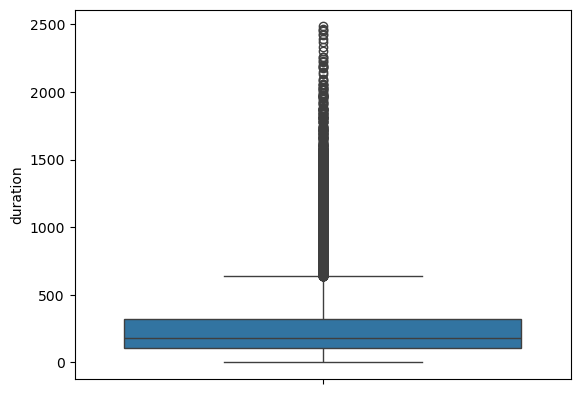

In [61]:
sns.boxplot(y='duration', data=bank_marketing)

In [62]:
bank_marketing = bank_marketing[bank_marketing.duration < 2500]

**Duration above 2500 seem excessive we can remove them from the dataset**

<Axes: ylabel='age'>

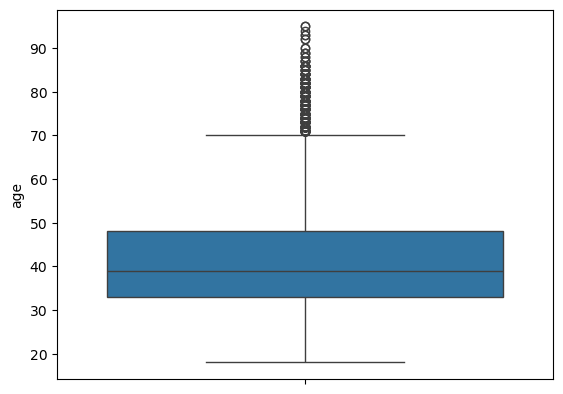

In [63]:
#Check for outliers in age column
sns.boxplot(y='age', data=bank_marketing)

<Axes: xlabel='age', ylabel='Count'>

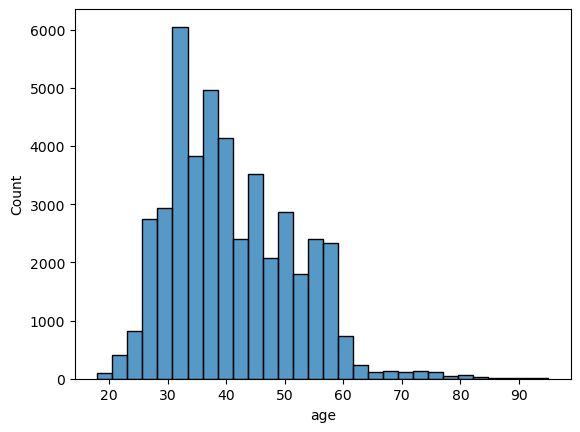

In [64]:
sns.histplot(bank_marketing['age'], bins=30)

**Though there is a handful of older people that is expected in real life**

<Axes: xlabel='balance', ylabel='Count'>

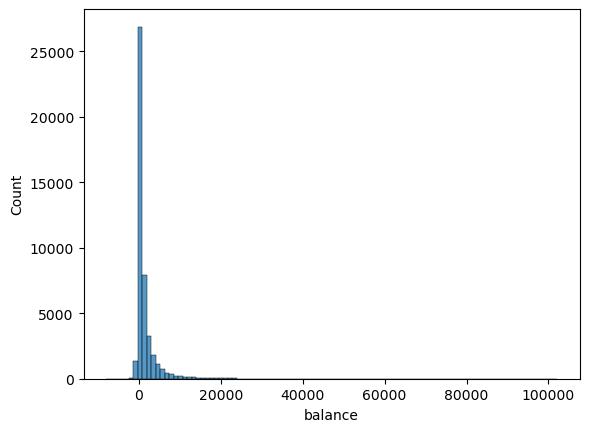

In [65]:
sns.histplot(bank_marketing['balance'], bins=100)

**There is a skew in the balance column, this is usually expected**

### Exploratory Data Analysis

Here, I am going to explore the data to understand our data and find patterns to help the model learn better by reducing multicollinearity and finding possibilities for feature engineering and selection. 

1. 